In [1]:
import os
from pathlib import Path
import random
import time
import numpy as np
import pandas as pd
from PIL import Image, ImageFile
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
from torchvision import transforms
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score
)
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True
plt.rcParams['figure.dpi'] = 100

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("Torch CUDA version:", torch.version.cuda)
print("Torch version:", torch.__version__)

CUDA available: True
GPU: Tesla T4
Torch CUDA version: 12.8
Torch version: 2.10.0+cu128


In [2]:
# ── Paths ────────────────────────────────────────────────────────────
BASE_DIR   = Path('/kaggle/input/datasets/raghavdharwal/pelgass-bay-of-biscay-zooscan-zooplankton-dataset')
CSV_META   = BASE_DIR / '101139.csv'   # column dictionary
CSV_COUNTS = BASE_DIR / '101140.csv'   # class counts
IMAGE_ROOT = BASE_DIR / '101141' / 'individual_images'

In [3]:
# ── Training hyper-parameters ────────────────────────────────────────
IMG_SIZE      = 128
BATCH_SIZE    = 128
EPOCHS        = 10
LR            = 1e-3
SEED          = 42
MAX_SAMPLES   = None   # Set an int (e.g. 200_000) for quicker experiments
NUM_WORKERS   = 4
TOP_K_CLASSES = 20     # classes shown on bar charts

In [4]:
# ── Class distribution ───────────────────────────────────────────────
counts_df = pd.read_csv(CSV_COUNTS, sep=';')
counts_df.columns = ['taxon', 'total_counts', 'label_type']
counts_df = counts_df.sort_values('total_counts', ascending=False).reset_index(drop=True)

print(f'101140.csv — {len(counts_df)} classes, {counts_df["total_counts"].sum():,} total images')
print(f'Taxonomy classes : {(counts_df.label_type == "T").sum()}')
print(f'Morphological    : {(counts_df.label_type == "M").sum()}')
display(counts_df.head(15))

101140.csv — 127 classes, 1,153,452 total images
Taxonomy classes : 75
Morphological    : 52


,taxon,total_counts,label_type
0,detritus,219541,M
1,Calanoida,149956,T
2,Oithonidae,110510,T
3,Calanidae,91513,T
4,Acartiidae,66353,T
5,artefact,60718,M
6,Oncaeidae,34651,T
7,badfocus_artefact,34507,M
8,Appendicularia,34027,T
9,Temoridae,31335,T


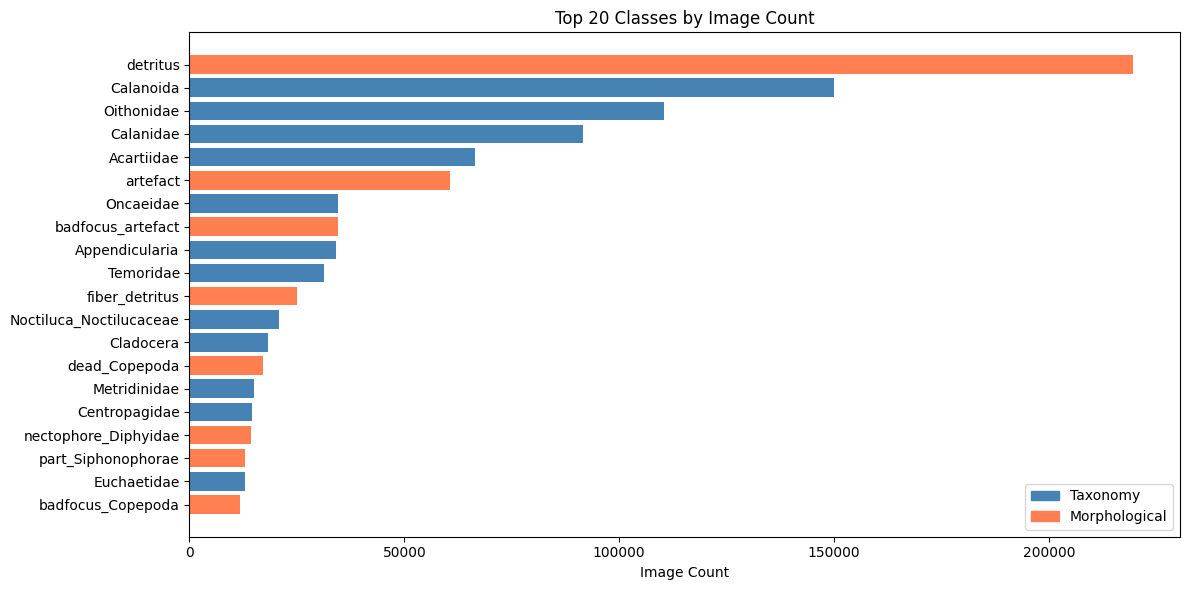


Count statistics per class:
count       127.000000
mean       9082.299213
std       27760.190444
min           1.000000
25%         117.500000
50%         695.000000
75%        4243.000000
max      219541.000000
Name: total_counts, dtype: float64


In [5]:
# ── Top-K class distribution bar chart ───────────────────────────────
top_k = counts_df.head(TOP_K_CLASSES)

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['steelblue' if t == 'T' else 'coral' for t in top_k['label_type']]
ax.barh(top_k['taxon'][::-1], top_k['total_counts'][::-1], color=colors[::-1])
ax.set_xlabel('Image Count')
ax.set_title(f'Top {TOP_K_CLASSES} Classes by Image Count')
ax.legend(handles=[
    plt.Rectangle((0,0),1,1, color='steelblue', label='Taxonomy'),
    plt.Rectangle((0,0),1,1, color='coral', label='Morphological'),
])
plt.tight_layout()
plt.show()

print('\nCount statistics per class:')
print(counts_df['total_counts'].describe())

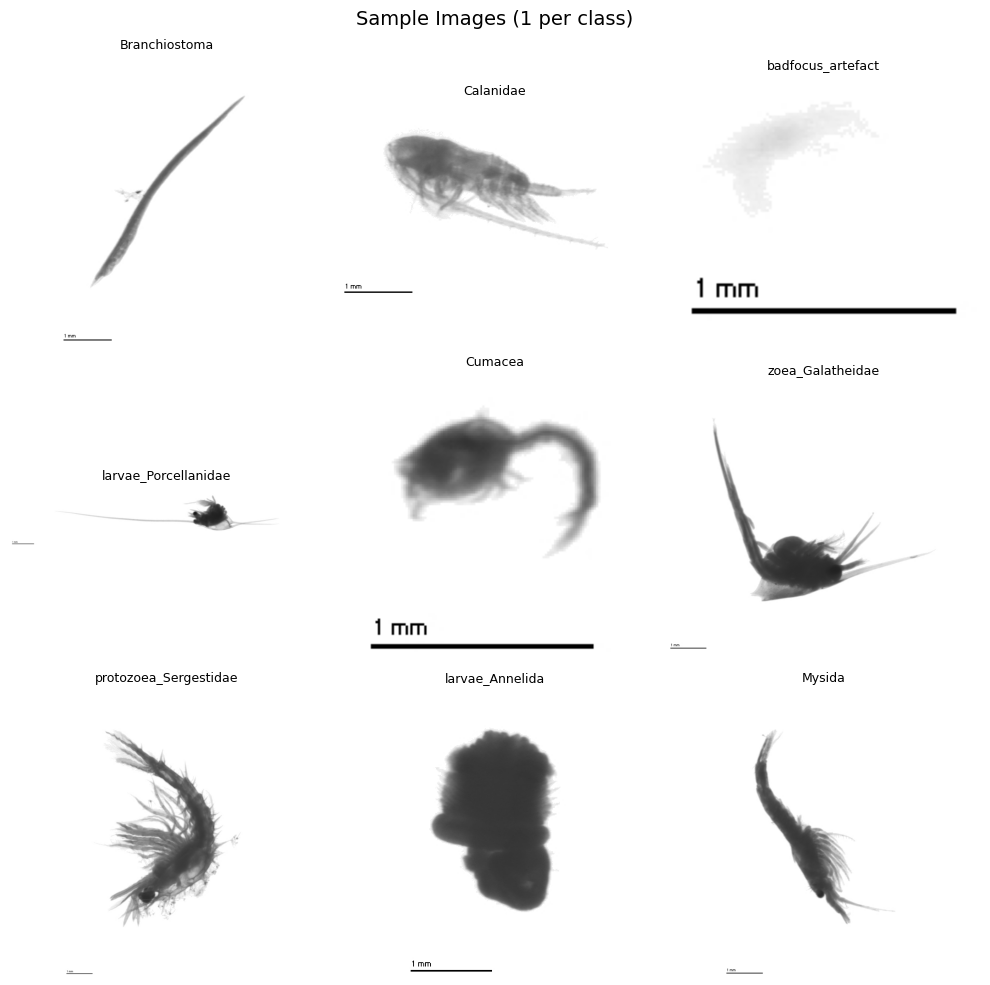

In [6]:
# ── Show sample images from 9 random classes ─────────────────────────
rng = np.random.default_rng(SEED)
sample_classes = rng.choice(sorted(os.listdir(IMAGE_ROOT)), size=15, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, cls_folder in zip(axes.flat, sample_classes):
    cls_path = IMAGE_ROOT / cls_folder
    imgs = sorted(cls_path.glob('*.jpg'))
    if imgs:
        img = Image.open(imgs[0]).convert('RGB')
        ax.imshow(img)
    ax.set_title(cls_folder.split('__')[0], fontsize=9)
    ax.axis('off')
plt.suptitle('Sample Images (1 per class)', fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
# Build index via torchvision ImageFolder
print(f"Indexing images at {IMAGE_ROOT}... this may take a few minutes on Kaggle due to 1M+ files.")
start_time = time.time()

base_dataset = ImageFolder(IMAGE_ROOT)

end_time = time.time()
num_classes = len(base_dataset.classes)
all_indices = np.arange(len(base_dataset))

print(f'Indexing completed in {end_time - start_time:.2f} seconds.')

# Optionally subsample
if MAX_SAMPLES is not None and MAX_SAMPLES < len(all_indices):
    rng = np.random.default_rng(SEED)
    all_indices = rng.choice(all_indices, size=MAX_SAMPLES, replace=False)

rng = np.random.default_rng(SEED)
rng.shuffle(all_indices)

# 80 / 10 / 10 split
n_total = len(all_indices)
n_train = int(0.8 * n_total)
n_val   = int(0.1 * n_total)

train_idx = all_indices[:n_train]
val_idx   = all_indices[n_train:n_train + n_val]
test_idx  = all_indices[n_train + n_val:]

print(f'Classes : {num_classes}')
print(f'Total   : {n_total:,}')
print(f'Train   : {len(train_idx):,}')
print(f'Val     : {len(val_idx):,}')
print(f'Test    : {len(test_idx):,}')

Indexing images at /kaggle/input/datasets/raghavdharwal/pelgass-bay-of-biscay-zooscan-zooplankton-dataset/101141/individual_images... this may take a few minutes on Kaggle due to 1M+ files.
Indexing completed in 1139.86 seconds.
Classes : 127
Total   : 1,153,507
Train   : 922,805
Val     : 115,350
Test    : 115,352


In [8]:
# ── Transforms ────────────────────────────────────────────────────────
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


# ── Custom Dataset wrapper ────────────────────────────────────────────
class IndexedImageDataset(Dataset):
    """Wraps ImageFolder with a subset of indices and a custom transform."""
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        base_idx = self.indices[idx]
        path, target = self.base_dataset.samples[base_idx]
        image = self.base_dataset.loader(path)
        if self.transform:
            image = self.transform(image)
        return image, target


# ── Create DataLoaders ────────────────────────────────────────────────
train_ds = IndexedImageDataset(base_dataset, train_idx, transform=train_transform)
val_ds   = IndexedImageDataset(base_dataset, val_idx,   transform=eval_transform)
test_ds  = IndexedImageDataset(base_dataset, test_idx,  transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f'Batches per epoch — train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}')

Batches per epoch — train: 7210, val: 902, test: 902


In [9]:
# Filter classes with at least 100 images
MIN_IMAGES = 100
valid_taxons = counts_df[counts_df['total_counts'] >= MIN_IMAGES]['taxon'].tolist()

print(f'Original classes: {len(counts_df)}')
print(f'Classes with >= {MIN_IMAGES} images: {len(valid_taxons)}')

# Create a list of valid folder names (which include the ID suffix in the directory structure)
all_folders = os.listdir(IMAGE_ROOT)
valid_folders = [f for f in all_folders if f.split('__')[0] in valid_taxons]

print(f'Matching folders found: {len(valid_folders)}')


Original classes: 127
Classes with >= 100 images: 96
Matching folders found: 95


In [10]:
# We will use a custom Dataset to filter the ImageFolder without moving physical files
class FilteredImageFolder(ImageFolder):
    def __init__(self, root, valid_folders, transform=None):
        self.valid_folders = set(valid_folders)
        super().__init__(root, transform=transform)

    def find_classes(self, directory):
        classes, class_to_idx = super().find_classes(directory)
        # Keep only the classes that are in our valid_folders list
        filtered_classes = [c for c in classes if c in self.valid_folders]
        filtered_class_to_idx = {cls_name: i for i, cls_name in enumerate(sorted(filtered_classes))}
        return filtered_classes, filtered_class_to_idx

# Rebuild the base dataset with the filter
base_dataset = FilteredImageFolder(str(IMAGE_ROOT), valid_folders)

num_classes = len(base_dataset.classes)
all_indices = np.arange(len(base_dataset))

print(f'Filtered Classes: {num_classes}')
print(f'Total Images Remaining: {len(all_indices):,}')


Filtered Classes: 95
Total Images Remaining: 1,152,443


```markdown
Now that we have the filtered `base_dataset`, we need to re-run the splitting logic to update `train_idx`, `val_idx`, and `test_idx` based on the new total count.
```

In [11]:
# Re-split the filtered dataset
if MAX_SAMPLES is not None and MAX_SAMPLES < len(all_indices):
    rng = np.random.default_rng(SEED)
    all_indices = rng.choice(all_indices, size=MAX_SAMPLES, replace=False)

rng = np.random.default_rng(SEED)
rng.shuffle(all_indices)

n_total = len(all_indices)
n_train = int(0.8 * n_total)
n_val   = int(0.1 * n_total)

train_idx = all_indices[:n_train]
val_idx   = all_indices[n_train:n_train + n_val]
test_idx  = all_indices[n_train + n_val:]

# Update DataLoaders
train_ds = IndexedImageDataset(base_dataset, train_idx, transform=train_transform)
val_ds   = IndexedImageDataset(base_dataset, val_idx,   transform=eval_transform)
test_ds  = IndexedImageDataset(base_dataset, test_idx,  transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f'New Train size: {len(train_ds):,}')
print(f'New Val size  : {len(val_ds):,}')
print(f'New test size : {len(test_ds):,}')
print(f'Batches per epoch — train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}')

New Train size: 921,954
New Val size  : 115,244
New test size : 115,245
Batches per epoch — train: 7203, val: 901, test: 901


/tmp/ipykernel_24/1718780599.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_k_filtered, y='taxon', x='count', palette='viridis')


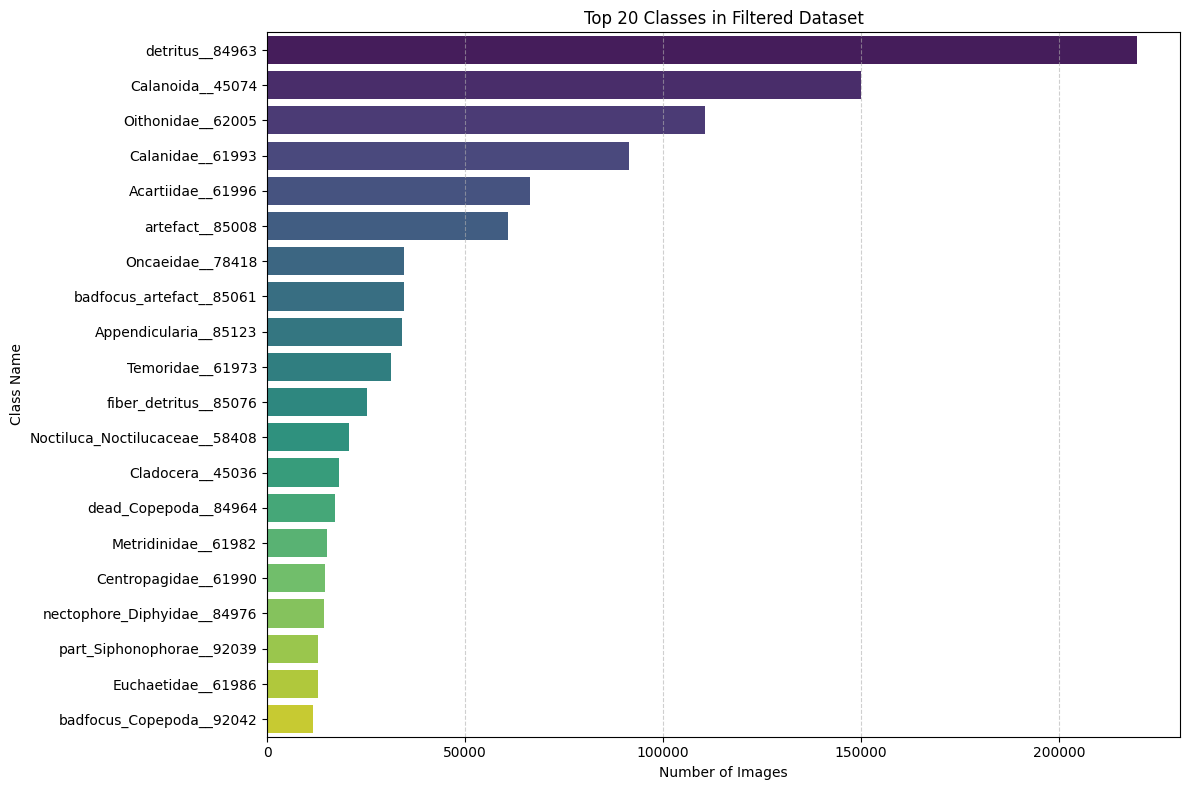

Total images in filtered dataset: 1,152,443
Minimum images in a class: 114


In [12]:
# Calculate counts for the filtered dataset
filtered_class_counts = {}
for _, target in base_dataset.samples:
    class_name = base_dataset.classes[target]
    filtered_class_counts[class_name] = filtered_class_counts.get(class_name, 0) + 1

# Convert to DataFrame for easier plotting
filtered_counts_df = pd.DataFrame(list(filtered_class_counts.items()), columns=['taxon', 'count'])
filtered_counts_df = filtered_counts_df.sort_values('count', ascending=False).reset_index(drop=True)

# Plot top classes
top_k_filtered = filtered_counts_df.head(TOP_K_CLASSES)

plt.figure(figsize=(12, 8))
sns.barplot(data=top_k_filtered, y='taxon', x='count', palette='viridis')
plt.title(f'Top {TOP_K_CLASSES} Classes in Filtered Dataset')
plt.xlabel('Number of Images')
plt.ylabel('Class Name')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Total images in filtered dataset: {filtered_counts_df['count'].sum():,}")
print(f"Minimum images in a class: {filtered_counts_df['count'].min()}")


In [13]:
import torchvision.models as models

# Load pretrained MobileNetV3-Small
model = models.mobilenet_v3_small(weights='IMAGENET1K_V1')
# Freeze feature extraction layers
for param in model.parameters():
    param.requires_grad = False

# Replace the classifier head
# MobileNetV3 small classifier is a Sequential:
# [Linear(in_features, intermediate), Hardswish(), Dropout(...), Linear(intermediate, out_features)]
num_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(num_features, num_classes)

# Move to device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = model.to(device)

print(f'Model initialized with {num_classes} output units.')
print(f'Device: {device}')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 105MB/s]


Model initialized with 95 output units.
Device: cuda


In [14]:
# Calculate class weights for imbalance
# weight = 1.0 / sqrt(count)

# Ensure the order matches base_dataset.classes
class_counts = filtered_counts_df.set_index('taxon')['count'].to_dict()
counts_tensor = torch.tensor(
    [class_counts[c] for c in base_dataset.classes],
    dtype=torch.float
)

# Smooth imbalance
weights = 1.0 / torch.sqrt(counts_tensor)

# Normalize (optional but good)
weights = weights / weights.sum() * len(weights)

weights = weights.to(device)

criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LR)

print("Weights calculated and CrossEntropyLoss initialized with class weights.")
print(f"Detritus weight: {weights[base_dataset.classes.index('detritus__84963')].item():.6f}")
print(f"Minimum count class weight: {weights.cpu().max().item():.6f}")

Weights calculated and CrossEntropyLoss initialized with class weights.
Detritus weight: 0.065074
Minimum count class weight: 2.855681


In [15]:
import os
import torch
from tqdm import tqdm

# ==============================
# ⚙️ CONFIG
# ==============================
EPOCHS = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Kaggle paths
WORKING_CKPT = "/kaggle/working/mobilenet_v3_small_best.pth"
INPUT_CKPT = "/kaggle/input/pelgas-checkpoints/mobilenet_v3_small_best.pth"  # optional

# ==============================
# 📦 INIT
# ==============================
model = model.to(device)
best_val_acc = 0.0
start_epoch = 0
history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

# ==============================
# 🔁 SMART RESUME LOGIC
# ==============================
load_path = None

if os.path.exists(WORKING_CKPT):
    load_path = WORKING_CKPT
elif os.path.exists(INPUT_CKPT):
    load_path = INPUT_CKPT

if load_path:
    print(f"🔁 Loading checkpoint from: {load_path}")
    checkpoint = torch.load(load_path, map_location=device)

    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint['val_acc']
    history = checkpoint.get('history', history)

    print(f"Resumed from epoch {start_epoch}, best Val Acc: {best_val_acc:.2f}%")
else:
    print("🚀 Starting fresh training")

# ==============================
# 🧠 TRAIN LOOP
# ==============================
print(f"Training for {EPOCHS} epochs...")

for epoch in range(start_epoch, EPOCHS):

    # -------- TRAIN --------
    model.train()
    running_loss = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")

    for images, labels in train_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        train_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    epoch_train_loss = running_loss / len(train_loader)

    # -------- VALIDATION --------
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]")

        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            preds = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    epoch_val_loss = val_loss / len(val_loader)
    epoch_val_acc = 100 * correct / total

    # -------- TRACK --------
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)

    print(f"\n📊 Epoch {epoch+1}: "
          f"Train Loss={epoch_train_loss:.4f} | "
          f"Val Loss={epoch_val_loss:.4f} | "
          f"Val Acc={epoch_val_acc:.2f}%")

    # ==============================
    # 💾 SAVE BEST MODEL (CPU SAFE)
    # ==============================
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc

        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc,
            'history': history
        }, WORKING_CKPT)

        print(f"✅ Best model saved → {WORKING_CKPT}")

# ==============================
# 📤 FINAL EXPORT (CRITICAL)
# ==============================
print("\n⚠️ IMPORTANT:")
print("Go to Kaggle → 'Save Version' → Check 'Output' → This saves your model permanently.")

🚀 Starting fresh training
Training for 10 epochs...


Epoch 1/10 [Train]:   4%|▎         | 269/7203 [01:05<23:48,  4.85it/s, loss=2.3823]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Epoch 1/10 [Val]: 100%|██████████| 901/901 [03:40<00:00,  4.09it/s]



📊 Epoch 1: Train Loss=2.3944 | Val Loss=2.1994 | Val Acc=47.91%
✅ Best model saved → /kaggle/working/mobilenet_v3_small_best.pth


Epoch 2/10 [Train]:  43%|████▎     | 3114/7203 [08:40<11:44,  5.80it/s, loss=2.0182]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Epoch 2/10 [Val]: 100%|██████████| 901/901 [01:50<00:00,  8.18it/s]



📊 Epoch 2: Train Loss=2.3095 | Val Loss=2.1712 | Val Acc=48.08%
✅ Best model saved → /kaggle/working/mobilenet_v3_small_best.pth


...


📊 Epoch 8: Train Loss=2.3012 | Val Loss=2.1439 | Val Acc=48.59%


Epoch 9/10 [Train]:  71%|███████   | 5124/7203 [14:22<05:53,  5.88it/s, loss=2.3087]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Epoch 9/10 [Val]: 100%|██████████| 901/901 [02:04<00:00,  7.24it/s]



📊 Epoch 9: Train Loss=2.3057 | Val Loss=2.1640 | Val Acc=47.76%


Epoch 10/10 [Train]:  67%|██████▋   | 4817/7203 [13:13<06:03,  6.56it/s, loss=2.1997]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Epoch 10/10 [Val]: 100%|██████████| 901/901 [01:51<00:00,  8.11it/s]


📊 Epoch 10: Train Loss=2.3017 | Val Loss=2.1287 | Val Acc=48.94%

⚠️ IMPORTANT:
Go to Kaggle → 'Save Version' → Check 'Output' → This saves your model permanently.


In [16]:
import os
import torch
from tqdm import tqdm

# ==============================
# 📁 PATH (Kaggle-safe)
# ==============================
FT_CKPT = "/kaggle/working/mobilenet_v3_small_finetuned_best.pth"

# ==============================
# 🔓 UNFREEZE MODEL
# ==============================
for param in model.parameters():
    param.requires_grad = True

# Lower LR for fine-tuning
FINE_TUNE_LR = 1e-5
optimizer = torch.optim.Adam(model.parameters(), lr=FINE_TUNE_LR)

print("Model unfrozen. Fine-tuning started.")

# ==============================
# 🔁 RESUME LOGIC (important)
# ==============================
best_val_acc_ft = best_val_acc  # from phase 1
start_epoch = 0

if os.path.exists(FT_CKPT):
    print(f"🔁 Loading fine-tuned checkpoint from {FT_CKPT}")
    checkpoint = torch.load(FT_CKPT, map_location=device)

    model.load_state_dict(checkpoint['model_state_dict'])
    best_val_acc_ft = checkpoint['val_acc']

    print(f"Resumed FT with best acc: {best_val_acc_ft:.2f}%")

# ==============================
# 🧠 TRAIN LOOP
# ==============================
FT_EPOCHS = 10

for epoch in range(start_epoch, FT_EPOCHS):

    # -------- TRAIN --------
    model.train()
    running_loss = 0.0

    train_bar = tqdm(train_loader, desc=f"FT Epoch {epoch+1}/{FT_EPOCHS} [Train]")

    for images, labels in train_bar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        train_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    # -------- VALIDATION --------
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        val_bar = tqdm(val_loader, desc=f"FT Epoch {epoch+1} [Val]")

        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            preds = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (preds == labels).sum().item()

    val_acc = 100 * correct / total

    print(f"\n📊 Fine-tune Epoch {epoch+1}: Val Acc = {val_acc:.2f}%")

    # ==============================
    # 💾 SAVE BEST MODEL
    # ==============================
    if val_acc > best_val_acc_ft:
        best_val_acc_ft = val_acc

        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc_ft,
            'phase': 'fine-tuning'
        }, FT_CKPT)

        print(f"✅ Best fine-tuned model saved → {FT_CKPT}")

Model unfrozen. Fine-tuning started.


FT Epoch 1/10 [Train]:  66%|██████▌   | 4768/7203 [13:12<06:45,  6.00it/s, loss=1.5681]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
FT Epoch 1 [Val]: 100%|██████████| 901/901 [01:52<00:00,  8.03it/s]



📊 Fine-tune Epoch 1: Val Acc = 61.87%
✅ Best fine-tuned model saved → /kaggle/working/mobilenet_v3_small_finetuned_best.pth


FT Epoch 2/10 [Train]:  97%|█████████▋| 6997/7203 [19:41<00:32,  6.33it/s, loss=1.3185]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
FT Epoch 2 [Val]: 100%|██████████| 901/901 [01:52<00:00,  8.02it/s]



📊 Fine-tune Epoch 2: Val Acc = 66.42%
✅ Best fine-tuned model saved → /kaggle/working/mobilenet_v3_small_finetuned_best.pth


...


📊 Fine-tune Epoch 8: Val Acc = 74.96%
✅ Best fine-tuned model saved → /kaggle/working/mobilenet_v3_small_finetuned_best.pth


FT Epoch 9/10 [Train]:  25%|██▍       | 1798/7203 [05:42<15:18,  5.88it/s, loss=1.2000]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
FT Epoch 9 [Val]: 100%|██████████| 901/901 [02:58<00:00,  5.04it/s]



📊 Fine-tune Epoch 9: Val Acc = 76.16%
✅ Best fine-tuned model saved → /kaggle/working/mobilenet_v3_small_finetuned_best.pth


FT Epoch 10/10 [Train]:   3%|▎         | 204/7203 [01:07<29:56,  3.90it/s, loss=0.8889]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101287765 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
FT Epoch 10 [Val]: 100%|██████████| 901/901 [02:06<00:00,  7.13it/s]


📊 Fine-tune Epoch 10: Val Acc = 76.22%
✅ Best fine-tuned model saved → /kaggle/working/mobilenet_v3_small_finetuned_best.pth


In [17]:
import os
import json
import torch
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import classification_report, f1_score, accuracy_score

# ==============================
# 📁 PATH (Kaggle-safe)
# ==============================
FT_CKPT = "/kaggle/working/mobilenet_v3_small_finetuned_best.pth"

# ==============================
# 🔁 LOAD BEST MODEL
# ==============================
if os.path.exists(FT_CKPT):
    checkpoint = torch.load(FT_CKPT, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"✅ Loaded best fine-tuned model | Val Acc: {checkpoint['val_acc']:.2f}%")
else:
    print("⚠️ No fine-tuned checkpoint found. Using current model.")

model.eval()

# ==============================
# 🧠 INFERENCE
# ==============================
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating Test Set"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ==============================
# 📊 METRICS
# ==============================
accuracy = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average='macro')

print(f"\n🎯 Final Test Accuracy: {accuracy*100:.2f}%")
print(f"🎯 Final Macro F1 Score: {macro_f1:.4f}")

# ==============================
# 📋 CLASS REPORT
# ==============================
report = classification_report(
    all_labels,
    all_preds,
    target_names=base_dataset.classes,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

# ==============================
# 🔍 FAILURE INTELLIGENCE (key upgrade)
# ==============================
low_recall_df = report_df[
    (report_df.index != "accuracy") &
    (report_df["recall"] < 0.50)
].sort_values("recall")

print("\n🚨 Classes with Recall < 50%")
if low_recall_df.empty:
    print("None — all classes above 50% recall ✅")
else:
    display(low_recall_df[['recall', 'f1-score', 'support']])

# ==============================
# 🧾 SAVE RESULTS (persistent)
# ==============================
report_df.to_csv("/kaggle/working/classification_report.csv")

with open("/kaggle/working/metrics.json", "w") as f:
    json.dump({
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }, f)

print("\n💾 Results saved → /kaggle/working/")
print("⚠️ Use 'Save Version' → Output to persist")

✅ Loaded best fine-tuned model | Val Acc: 76.22%


Evaluating Test Set: 100%|██████████| 901/901 [05:15<00:00,  2.85it/s]



🎯 Final Test Accuracy: 76.33%
🎯 Final Macro F1 Score: 0.5449

🚨 Classes with Recall < 50%


,recall,f1-score,support
larvae_Crustacea__85114,0.000000,0.000000,11.0
part_Annelida__84966,0.000000,0.000000,11.0
bract_Diphyidae__92230,0.043478,0.064516,46.0
part_Cnidaria__84970,0.097222,0.102190,72.0
Euphausiacea__45041,0.142857,0.192513,126.0
Decapoda__45043,0.152542,0.162162,59.0
multiple_Copepoda__85044,0.168317,0.165049,101.0
tail_Chaetognatha__84968,0.210526,0.156863,19.0
Heterorhabdidae__61985,0.222222,0.216216,18.0
Pontellidae__61980,0.241379,0.245614,29.0



💾 Results saved → /kaggle/working/
⚠️ Use 'Save Version' → Output to persist


In [18]:
#!pip install -q onnx onnx2tf tensorflow tensorflow-probability

In [19]:
# ==============================
# 📁 PATHS (Kaggle-safe)
# ==============================
ONNX_PATH = "/kaggle/working/model.onnx"
TFLITE_DIR = "/kaggle/working/tflite_model"

import os
import torch
import torch.onnx

os.makedirs(TFLITE_DIR, exist_ok=True)

# ==============================
# 🧠 EXPORT TO ONNX
# ==============================
model.eval()

dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params=True,
    opset_version=12,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output']
)

print(f"✅ ONNX saved → {ONNX_PATH}")

# ==============================
# 🔁 ONNX → TFLITE
# ==============================
import onnx2tf

onnx2tf.convert(
    input_onnx_file_path=ONNX_PATH,
    output_folder_path=TFLITE_DIR,
    copy_onnx_input_output_names_to_tflite=True,
    non_verbose=True
)

print(f"✅ TFLite model saved → {TFLITE_DIR}")
print("⚠️ Save Version → Output to persist files")

ModuleNotFoundError: No module named 'onnxscript'